Лабораторна робота № 2

![Alt text](img.jpg)


Студента групи КН-315

Лозового О.А.

In [1]:
import random

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv('data.csv')
df = df.drop(df.columns[94], axis=1)
# df = df.sample(frac=1)
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,0.035490


In [3]:
for i in df.columns:
  print(i, ' - ', df[i].isna().sum())

Bankrupt?  -  0
 ROA(C) before interest and depreciation before interest  -  0
 ROA(A) before interest and % after tax  -  0
 ROA(B) before interest and depreciation after tax  -  0
 Operating Gross Margin  -  0
 Realized Sales Gross Margin  -  0
 Operating Profit Rate  -  0
 Pre-tax net Interest Rate  -  0
 After-tax net Interest Rate  -  0
 Non-industry income and expenditure/revenue  -  0
 Continuous interest rate (after tax)  -  0
 Operating Expense Rate  -  0
 Research and development expense rate  -  0
 Cash flow rate  -  0
 Interest-bearing debt interest rate  -  0
 Tax rate (A)  -  0
 Net Value Per Share (B)  -  0
 Net Value Per Share (A)  -  0
 Net Value Per Share (C)  -  0
 Persistent EPS in the Last Four Seasons  -  0
 Cash Flow Per Share  -  0
 Revenue Per Share (Yuan ¥)  -  0
 Operating Profit Per Share (Yuan ¥)  -  0
 Per Share Net profit before tax (Yuan ¥)  -  0
 Realized Sales Gross Profit Growth Rate  -  0
 Operating Profit Growth Rate  -  0
 After-tax Net Profit Grow

In [4]:
train_len = 0.7
val_len = 0.15


traindf = df[:int(df.shape[0] * train_len) ]
valdf = df[int(df.shape[0] * train_len):int(df.shape[0] * (train_len + val_len))]
testdf = df[int(df.shape[0] * (train_len + val_len)):]

Нормалізація

In [5]:
mean_val = traindf.mean(axis=0)
std_val = traindf.std(axis=0)

print(mean_val, '\n', std_val)

Bankrupt?                                                   0.039388
 ROA(C) before interest and depreciation before interest    0.503307
 ROA(A) before interest and % after tax                     0.556685
 ROA(B) before interest and depreciation after tax          0.552174
 Operating Gross Margin                                     0.607802
                                                              ...   
 Net Income to Stockholder's Equity                         0.840212
 Liability to Equity                                        0.280754
 Degree of Financial Leverage (DFL)                         0.027792
 Interest Coverage Ratio (Interest expense to EBIT)         0.565302
 Equity to Liability                                        0.047747
Length: 95, dtype: float64 
 Bankrupt?                                                   0.194537
 ROA(C) before interest and depreciation before interest    0.061570
 ROA(A) before interest and % after tax                     0.067079
 ROA(

In [6]:
def norm(set, columns, mean_set, std_set): 
    for column in columns:
        mean = mean_set[column] 
        std = std_set[column] 
        tmp = []
        for x in set[column]:
            t = (x - mean) / std
            tmp.append(t)
        set[column] = tmp

In [7]:
cols = df.columns

norm(traindf, cols[1:], mean_val, std_val) 
norm(valdf, cols[1:], mean_val, std_val) 
norm(testdf, cols[1:], mean_val, std_val)

# print(testdf[df.columns[1]][-3:].values, '\n' ,df[df.columns[1]][-3:].values)
traindf.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,-2.155480,-1.972252,-2.321017,-0.344047,-0.343233,0.019502,-0.039141,-0.027687,-0.112916,...,-0.035474,-2.146089,-0.046709,-0.102264,-0.344169,-0.722516,0.554889,-0.063933,-0.086361,-0.586198
1,1,-0.633690,-0.275366,-0.561838,0.131924,0.133031,0.015427,0.011056,0.012724,0.000731,...,-0.035474,-0.265497,-0.046709,-0.024798,0.132093,-0.014212,0.181606,12.704406,0.336248,-0.505130
2,1,-1.254441,-0.859686,-1.266188,-0.344437,-0.348316,-0.000126,-0.088394,-0.062380,-0.189254,...,-0.035474,-0.759964,-0.046709,-0.005823,-0.344383,-0.201561,0.554105,-0.066397,-0.110099,-0.586097
3,1,-1.680416,-1.571599,-1.497012,-1.315526,-1.315313,-0.027784,-0.031014,-0.014838,-0.025107,...,-0.035474,-1.601720,-0.046709,-0.097277,-1.315627,-0.323366,0.056817,-0.058782,-0.044043,-0.445381
4,1,-0.621813,-0.272115,-0.473582,-0.489026,-0.488302,0.020192,0.009620,0.012970,-0.009441,...,-0.035474,-0.272240,-0.046709,-0.037935,-0.489043,-0.014008,-0.131554,-0.163128,0.711722,-0.229704


Побудова дерева

In [8]:
from sklearn import preprocessing
from sklearn import tree
from sklearn.decomposition import PCA

In [9]:
col_num = 0

X_train = traindf[cols[1:]].values
y_train = traindf[df.columns[col_num]].values
X_val = valdf[cols[1:]].values
y_val = valdf[df.columns[col_num]].values
X_test = testdf[cols[1:]].values
y_test = testdf[df.columns[col_num]].values

In [10]:
label_encoder = preprocessing.LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.fit_transform(y_test)
y_val = label_encoder.fit_transform(y_val)

In [11]:
def desicion_tree(depth, x, y):
    clf = tree.DecisionTreeClassifier(max_depth=depth)
    clf = clf.fit(x, y)
    tree.plot_tree(clf) 
    return clf

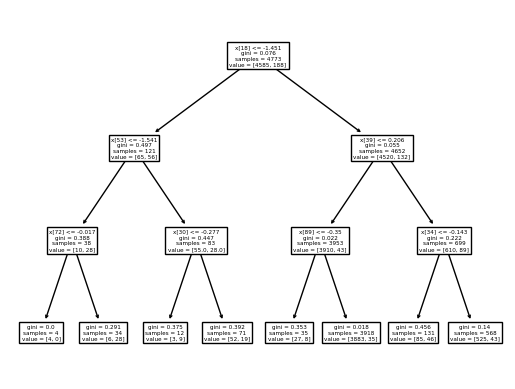

In [12]:
dep = 3
data = desicion_tree(dep, X_train, y_train)

In [13]:
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data.score(X_test, y_test)))

Depth 3, training dataset, SCORE (validation): 0.9844
Depth 3, training dataset, SCORE (test): 0.9814


Depth 20, training dataset, SCORE (validation): 0.9697
Depth 20, training dataset, SCORE (test): 0.9707


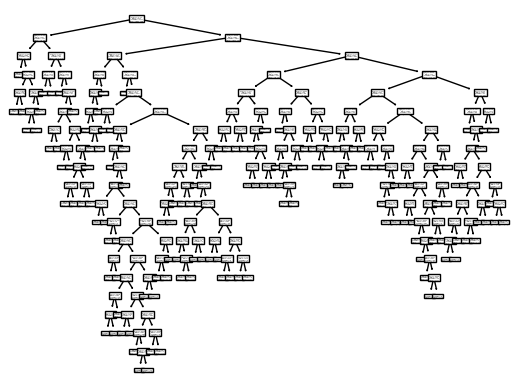

In [14]:
dep = 20
data1 = desicion_tree(dep, X_train, y_train)
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data1.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data1.score(X_test, y_test)))

Depth 1, training dataset, SCORE (validation): 0.9873
Depth 1, training dataset, SCORE (test): 0.9814


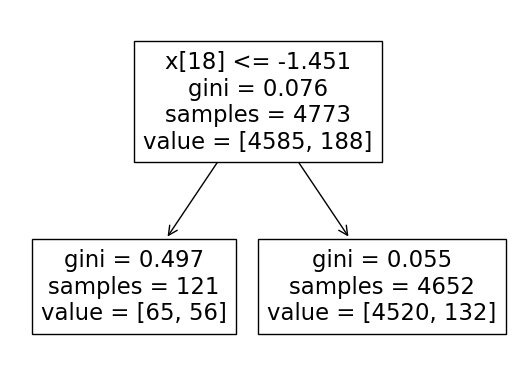

In [15]:
dep = 1
data2 = desicion_tree(dep, X_train, y_train)
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data2.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data2.score(X_test, y_test)))

Зашумлення

In [16]:
ntraindf = traindf.copy() 
cols1 = cols[1:]
for column in cols1:
    temp = []
    for x in ntraindf[column]:
        t = x + random.uniform(-0.1, 0.1)
        temp.append(t)
    ntraindf[column] = temp


Depth 3, training dataset, SCORE (validation): 0.9795
Depth 3, training dataset, SCORE (test): 0.9814


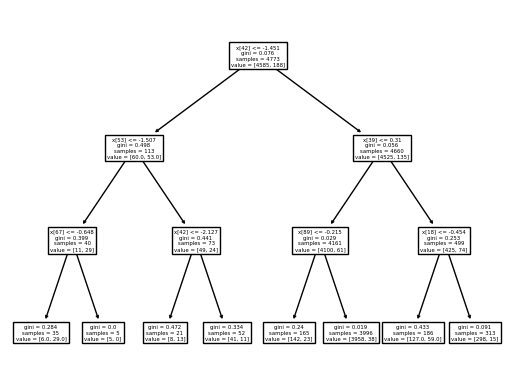

In [17]:
X_train_n = ntraindf[cols1]

dep = 3
data3 = desicion_tree(dep, X_train_n, y_train)
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data3.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data3.score(X_test, y_test)))

Depth 2, training dataset, SCORE (validation): 0.9814
Depth 2, training dataset, SCORE (test): 0.9814


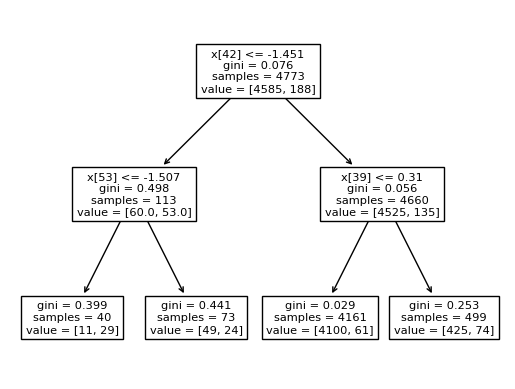

In [18]:
dep = 2
data4 = desicion_tree(dep, X_train_n, y_train)
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data4.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data4.score(X_test, y_test)))

Depth 1, training dataset, SCORE (validation): 0.9873
Depth 1, training dataset, SCORE (test): 0.9814


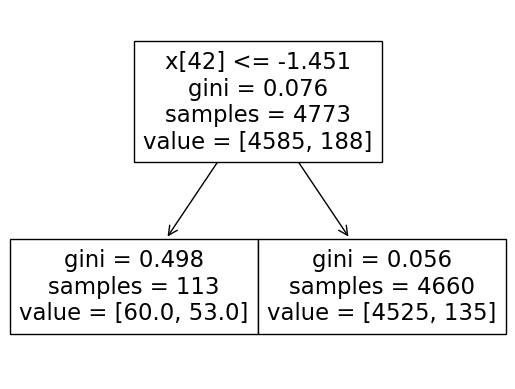

In [19]:
dep = 1
data5 = desicion_tree(dep, X_train_n, y_train)
print(f'Depth {dep}, training dataset, SCORE (validation):'
      , "{0:0.4f}".format(data5.score(X_val, y_val)))

print(f'Depth {dep}, training dataset, SCORE (test):'
      , "{0:0.4f}".format(data5.score(X_test, y_test)))

In [20]:
for i in traindf.columns:
  if(traindf[i].isna().sum() != 0):
    print(i)
  

З поданих вище дерев та їх точностей, можемо сказати:
1) при обраних мною глибинах немає overfitting
2) точність дерев рішень є високою(> 97%), а також можемо побачити, що найвище точність у дерева з найменою глибиною
3) точність валідаційної та тестової частини датасету є співмірними

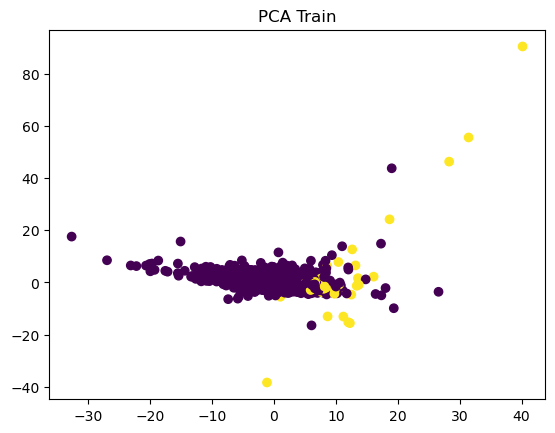

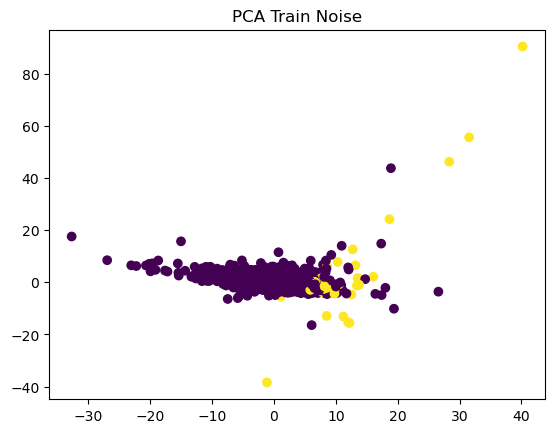

In [21]:
for x, name in [(traindf, 'Train'), (ntraindf, 'Train Noise')]: 
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(x)
    plt.figure()
    plt.scatter(X_pca[: ,0],
                X_pca[:, 1],
                c=x[cols[0]])
    plt.title(f'PCA {name}')
    plt.show()


Дані графіки показують, що зашумлений набір даних не сильно впливає на результатобчислень

Знешумлення

In [22]:
zeros_column = ntraindf['Bankrupt?']
ntraindf_no_zeros = ntraindf.iloc[:, 1:]

pca_n = PCA(0.95).fit(ntraindf_no_zeros)
components = pca_n.transform(ntraindf_no_zeros)
X_train_dn = pca_n.inverse_transform(components)
no_traindf = pd.DataFrame(data=X_train_dn, columns=ntraindf_no_zeros.columns)

no_traindf.insert(0, 'Bankrupt?', zeros_column)

no_traindf.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
0,1,-1.817941,-1.952779,-1.838560,-0.367559,-0.360912,-0.093906,-0.145490,-0.118004,-0.172928,...,0.486592,-2.120460,-0.018784,-0.093291,-0.361219,-0.805110,0.579608,-0.096577,-0.103097,-0.916199
1,1,-0.566692,-0.338590,-0.466845,0.136688,0.128845,0.042191,-0.006743,-0.006349,-0.068541,...,0.061806,-0.281064,-0.101502,-0.011843,0.133757,0.061510,0.085010,12.797415,0.385108,-0.869666
2,1,-1.312900,-1.119303,-1.198843,-0.365279,-0.345966,0.036802,-0.082385,-0.042925,-0.214464,...,-0.047780,-0.955384,-0.147597,0.043379,-0.352815,-0.067451,0.217256,-0.110869,-0.106057,-0.644484
3,1,-1.307678,-1.535827,-1.285781,-1.327149,-1.319447,-0.043139,-0.026105,-0.013689,0.010113,...,-0.047589,-1.488572,0.013612,-0.040098,-1.322297,-0.330037,0.058284,-0.153195,-0.022468,-0.310521
4,1,-0.347591,-0.364045,-0.327557,-0.538210,-0.533192,-0.003370,0.011751,0.011209,0.016757,...,-0.083932,-0.405225,-0.021728,-0.114712,-0.532650,-0.168336,-0.077306,-0.145782,0.672229,0.081690


Порівнявши з початковим датасетом після нормалізації, можемо сказати, що данні стали більш ближчими до початкових,нормалізованих, проте не повторюють їх

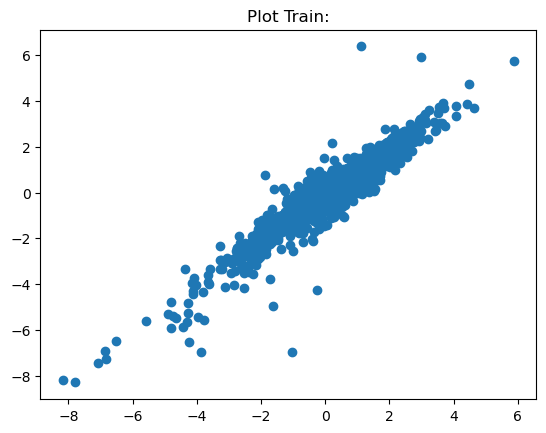

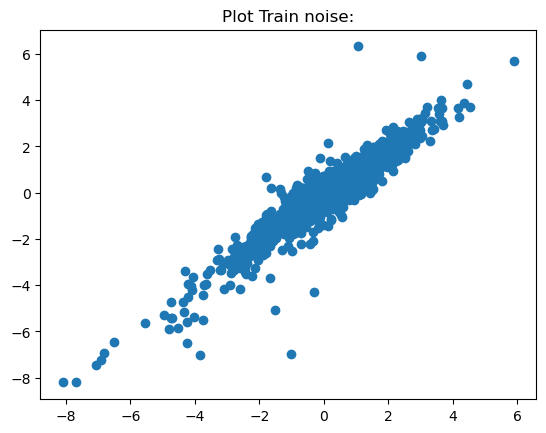

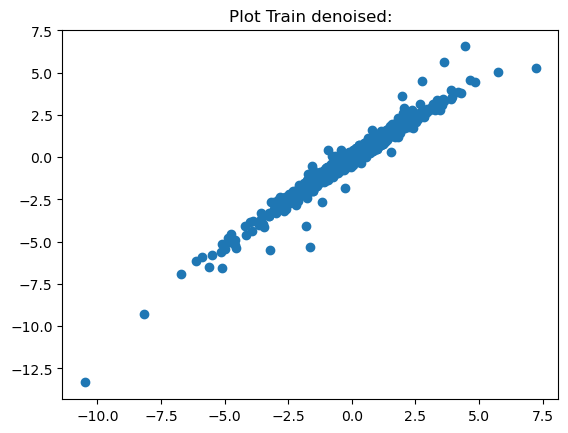

In [23]:
for x, name in zip([X_train, X_train_n, X_train_dn], ['Train', 'Train noise', 'Train denoised']):
    plt.scatter(x=np.array(x)[:, 0], y=np.array(x)[:, 1]) 
    plt.title(f'Plot {name}:')
    plt.show()

Depth 3, SCORE: 0.8286


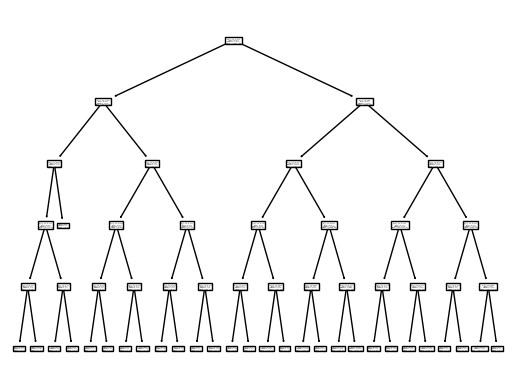

In [24]:
data = desicion_tree(5, X_train_n, y_train)
print('Depth 3, SCORE:', "{0:0.4f}".format(data1.score(X_train_n, y_train)))

Depth 10, SCORE: 0.7857


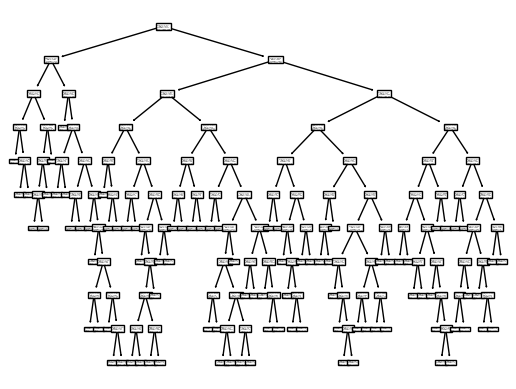

In [25]:
data = desicion_tree(10, X_train_dn, y_train)
print('Depth 10, SCORE:', "{0:0.4f}".format(data1.score(X_train_dn, y_train)))


Depth 1, SCORE: 0.7857


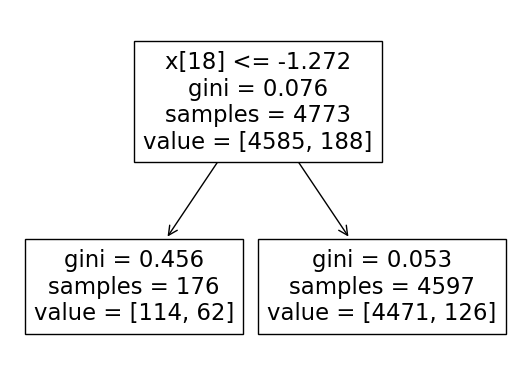

In [26]:
data = desicion_tree(1, X_train_dn, y_train)
print('Depth 1, SCORE:', "{0:0.4f}".format(data1.score(X_train_dn, y_train)))


Depth 100, SCORE: 0.7857


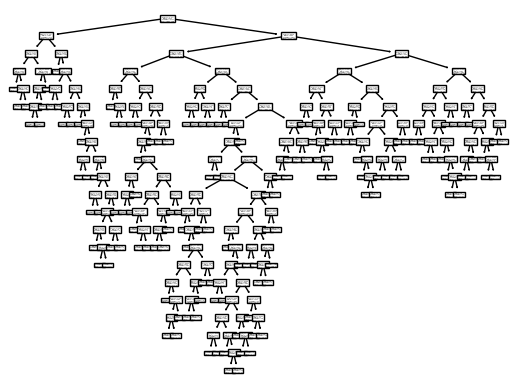

In [27]:
data = desicion_tree(100, X_train_dn, y_train)
print('Depth 100, SCORE:', "{0:0.4f}".format(data1.score(X_train_dn, y_train)))

З даних дерев, а точніше їх точності, можемо сказати, що на знешумлених данних, результати суттєво(на 20%) гірші ніж з початкових данних

Висновок: 

Модель дерева рішень показала високу точність на валідаційному та тестовому наборах даних.

Додавання шуму до навчального набору даних не суттєво вплинуло на результати PCA.

Застосування PCA для знешумлення даних дозволило зберегти основну інформацію та покращити роботу моделей на чистих даних.

Точність моделей на знешумлених даних є прийнятною, хоч і нижчою, ніж на початкових даних.

Отже, в даній роботі було успішно застосовано та порівняно моделі дерева рішень на різних варіантах наборів даних, що дозволило отримати важливі висновки щодо їх ефективності та стійкості до зашумлення.